# 06. Modelos Finais — Treinamento, Persistência e Inferência

**DCT1401 — Inteligência Artificial (UFRN, 2026.2)**
**Aluna:** Mariana dos Santos Batista Medeiros (Matrícula: 20230083988)

**Atividade 03 — Redes Neurais Artificiais com PyTorch: Classificação e Regressão**

Este notebook treina os modelos finais de regressão e de classificação com a configuração escolhida no Notebook 05, define o limiar de decisão da classificação na validação, salva os modelos em arquivos `.pt` com todo o pré-processamento necessário e demonstra que eles podem ser carregados e usados em um ambiente independente.

Os modelos da configuração de referência também são treinados e salvos, como base de comparação para a avaliação do Notebook 07.

**Uso do conjunto de teste.** Todas as decisões — configuração, semente, pesos e limiar — são tomadas sem consultar o teste e registradas antes de qualquer contato com ele. O teste é então usado em uma única etapa de avaliação final, com os quatro modelos já congelados (finais e de referência) e sem ajustes posteriores. Nessa etapa, a inferência sobre o teste é feita duas vezes para cada modelo — em memória e a partir do arquivo salvo — apenas para verificar a fidelidade do salvamento; nenhum resultado do teste altera qualquer escolha. As previsões do teste produzidas pelos modelos carregados são gravadas e reutilizadas no Notebook 07, sem nova inferência sobre o teste.

**Configuração do ambiente — Google Colab**

Esta etapa conecta o Google Colab ao Google Drive e configura os caminhos necessários para acessar o dataset original e os módulos Python do projeto.

In [3]:
from google.colab import drive
from pathlib import Path
import importlib
import os
import sys

drive.mount("/content/drive")
PROJETO = Path("/content/drive/MyDrive/projeto-cardiovascular-ia-03")

ARQUIVO_RAW = PROJETO / "data/raw/cardiovascular_disease_prediction.csv"
assert ARQUIVO_RAW.is_file(), f"Dataset original não encontrado: {ARQUIVO_RAW}"
for modulo in ["__init__.py", "pipeline_data.py", "models.py", "train.py", "metrics.py", "inference.py"]:
    assert (PROJETO / "src" / modulo).is_file(), f"Módulo ausente em src/: {modulo}"
for arquivo in ["logs/configuracao_final.json", "logs/hiperparametros.csv"]:
    assert (PROJETO / arquivo).is_file(), f"Arquivo do Notebook 05 ausente: {arquivo}"

os.chdir(PROJETO / "notebooks")
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

import src.pipeline_data as pipeline_data
import src.models as modelos_mlp
import src.metrics as metricas
import src.train as treino
import src.inference as inferencia
for modulo in (pipeline_data, modelos_mlp, metricas, treino, inferencia):
    importlib.reload(modulo)

pasta_modelos = PROJETO / "models"
pasta_referencia = pasta_modelos / "referencia"
pasta_tabelas = PROJETO / "reports" / "tables"
pasta_figuras = PROJETO / "reports" / "figures"
pasta_logs = PROJETO / "logs"
for pasta in (pasta_modelos, pasta_referencia, pasta_tabelas, pasta_figuras):
    pasta.mkdir(parents=True, exist_ok=True)
print("Projeto localizado em:", PROJETO)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto localizado em: /content/drive/MyDrive/projeto-cardiovascular-ia-03


In [4]:
import hashlib
import json
import platform
import subprocess
import tempfile

import numpy as np
import pandas as pd
import sklearn
import torch
from scipy.special import expit

DEVICE = "cpu"
ambiente = {
    "Modelo da CPU": treino.modelo_cpu(),
    "Threads do PyTorch": torch.get_num_threads(),
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "scikit-learn": sklearn.__version__,
    "GPU disponível": torch.cuda.is_available(),
    "Dispositivo utilizado": DEVICE,
}
display(pd.Series(ambiente, name="Valor").to_frame())

,Valor
Modelo da CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
Threads do PyTorch,1
Python,3.13.18
PyTorch,2.14.1+cpu
scikit-learn,1.6.1
GPU disponível,False
Dispositivo utilizado,cpu


## 1. Configurações e regras definidas antes do treinamento

São treinados quatro modelos: a **configuração final** (Notebook 05) e a **configuração de referência** (Notebooks 03 e 04), para cada problema. As regras abaixo são fixadas antes do treinamento e aplicadas apenas com dados de ajuste e validação.

**Semente.** Cada configuração foi avaliada com cinco sementes no Notebook 05, mas apenas as métricas foram guardadas. O modelo salvo é treinado novamente com a semente cuja métrica de validação é a **mediana** das cinco (RMSE na regressão; AP na classificação). Escolher a melhor semente favoreceria uma inicialização vantajosa por acaso; a mediana é representativa do desempenho típico da configuração. No mesmo processador, o novo treinamento deve reproduzir exatamente a métrica registrada no log do Notebook 05.

**Treinamento.** Como em todo o estudo: subconjunto de ajuste (12.800 registros), *early stopping* pela perda de validação e restauração do melhor estado. O modelo não é reajustado com a validação.

**Limiar de decisão (classificação).** O limiar é escolhido na validação, separadamente para cada modelo, como o valor que **maximiza o F1-score**, calculado de forma exata a partir da curva Precision–Recall. Entre limiares com o mesmo F1, escolhe-se o **menor**, que produz o maior Recall, já que, em triagem, um falso negativo tende a ser mais grave que um falso positivo. O F1 representa um compromisso específico entre Precision e Recall e não codifica custos clínicos; o limiar resultante é um **ponto de operação experimental**, e não um limiar clínico.

In [5]:
with open(pasta_logs / "configuracao_final.json", encoding="utf-8") as f:
    CONFIG_FINAL = json.load(f)

def cfg_de_json(c):
    return {**c, "hidden": tuple(c["hidden"])}

MODELOS = {}   # chave: (problema, papel)
for problema in ("regressao", "classificacao"):
    MODELOS[(problema, "final")] = treino.config_completa(cfg_de_json(CONFIG_FINAL[problema]["config"]))
    MODELOS[(problema, "referencia")] = treino.config_completa({})
    assert treino.id_configuracao(MODELOS[(problema, "final")]) == CONFIG_FINAL[problema]["config_id"]

display(pd.DataFrame([{
    "Problema": p, "Papel": papel, "config_id": treino.id_configuracao(cfg),
    "Camadas": "×".join(map(str, cfg["hidden"])), "Ativação": cfg["activation"], "Otimizador": cfg["otimizador"],
    "Taxa": cfg["lr"], "Batch": cfg["batch_size"], "Weight decay": cfg["weight_decay"], "Dropout": cfg["dropout"],
} for (p, papel), cfg in MODELOS.items()]).style.hide(axis="index"))

# Dados: a divisão completa é refeita; o teste permanece bruto e só é usado nas Seções 5 e 7
dados = pipeline_data.preparar_divisoes("../data/raw/cardiovascular_disease_prediction.csv")
DADOS_TAREFA = {p: treino.preparar_dados_tarefa(dados, p, incluir_teste=False)
                for p in ("regressao", "classificacao")}
for dt in DADOS_TAREFA.values():
    assert set(dt["X"]) == {"ajuste", "validacao"}
print("Divisão conferida; pré-processamento ajustado somente no ajuste; teste ainda não transformado.")

Problema,Papel,config_id,Camadas,Ativação,Otimizador,Taxa,Batch,Weight decay,Dropout
regressao,final,cfg_a7f13b5c34,32×32,ReLU,Adam,0.001000,32,0.001000,0.000000
regressao,referencia,cfg_8dff8c8b84,32×32,ReLU,Adam,0.001000,32,0.000000,0.000000
classificacao,final,cfg_a7f13b5c34,32×32,ReLU,Adam,0.001000,32,0.001000,0.000000
classificacao,referencia,cfg_8dff8c8b84,32×32,ReLU,Adam,0.001000,32,0.000000,0.000000


Divisão conferida; pré-processamento ajustado somente no ajuste; teste ainda não transformado.


## 2. Escolha da semente e treinamento dos modelos

A semente mediana é obtida do log do Notebook 05. Em seguida, cada modelo é treinado e a métrica de validação é comparada com a registrada no log para a mesma configuração e semente.

In [6]:
log = treino.carregar_log(PROJETO / "logs" / "hiperparametros.csv")
METRICA = {"regressao": "RMSE", "classificacao": "Average_Precision"}

SEMENTE, REGISTRO_LOG = {}, {}
for (problema, papel), cfg in MODELOS.items():
    cid = treino.id_configuracao(cfg)
    l = log[(log["problema"] == problema) & (log["config_id"] == cid)].sort_values("semente")
    assert sorted(l["semente"]) == list(treino.SEMENTES), (problema, papel)
    ordenado = l.sort_values([f"{METRICA[problema]}_validacao", "semente"]).reset_index(drop=True)
    linha = ordenado.loc[len(ordenado) // 2]
    SEMENTE[(problema, papel)] = int(linha["semente"])
    REGISTRO_LOG[(problema, papel)] = linha

display(pd.DataFrame([{
    "Problema": p, "Papel": papel, "Semente mediana": SEMENTE[(p, papel)],
    f"Métrica de validação no log": REGISTRO_LOG[(p, papel)][f"{METRICA[p]}_validacao"],
    "Processador do log": REGISTRO_LOG[(p, papel)]["dispositivo"],
} for (p, papel) in MODELOS]).style.format(precision=6).hide(axis="index"))

Problema,Papel,Semente mediana,Métrica de validação no log,Processador do log
regressao,final,2,2.952189,cpu (Intel(R) Xeon(R) CPU @ 2.20GHz)
regressao,referencia,3,2.954544,cpu (Intel(R) Xeon(R) CPU @ 2.20GHz)
classificacao,final,4,0.687980,cpu (Intel(R) Xeon(R) CPU @ 2.20GHz)
classificacao,referencia,3,0.687484,cpu (Intel(R) Xeon(R) CPU @ 2.20GHz)


In [7]:
REDES, RESULTADOS = {}, {}
linhas_treino = []
for (problema, papel), cfg in MODELOS.items():
    modelo, resultado, registro = treino.executar_configuracao(
        DADOS_TAREFA[problema], cfg, SEMENTE[(problema, papel)], device=DEVICE)
    assert not registro["divergiu"]
    REDES[(problema, papel)], RESULTADOS[(problema, papel)] = modelo, (resultado, registro)
    valor = registro["metricas_validacao"][METRICA[problema]]
    no_log = REGISTRO_LOG[(problema, papel)][f"{METRICA[problema]}_validacao"]
    linhas_treino.append({
        "Problema": problema, "Papel": papel, "Semente": SEMENTE[(problema, papel)],
        "Parâmetros": registro["n_parametros"], "Época do melhor estado": registro["epoca_melhor"],
        "Épocas executadas": registro["epocas_executadas"], "Tempo (s)": registro["tempo_s"],
        "Métrica de validação (agora)": valor, "Métrica de validação (log)": no_log,
        "Diferença absoluta": abs(valor - no_log),
    })
tabela_treino = pd.DataFrame(linhas_treino)
display(tabela_treino.style.format(precision=6).hide(axis="index"))
print(f"Processador desta sessão: cpu ({treino.modelo_cpu()})")
print("Diferença máxima em relação ao log:", tabela_treino["Diferença absoluta"].max())

Problema,Papel,Semente,Parâmetros,Época do melhor estado,Épocas executadas,Tempo (s),Métrica de validação (agora),Métrica de validação (log),Diferença absoluta
regressao,final,2,1313,18,38,28.036417,2.952189,2.952189,0.000000
regressao,referencia,3,1313,12,32,21.649651,2.954544,2.954544,0.000000
classificacao,final,4,1313,24,44,31.368700,0.687980,0.687980,0.000000
classificacao,referencia,3,1313,16,36,24.471016,0.687484,0.687484,0.000000


Processador desta sessão: cpu (Intel(R) Xeon(R) CPU @ 2.20GHz)
Diferença máxima em relação ao log: 0.0


No mesmo processador em que o log foi produzido, a diferença deve ser zero. Se a sessão estiver em outro processador, pequenas diferenças numéricas são esperadas (da ordem de $10^{-4}$ no RMSE, bem menores que a variação entre sementes); elas não alteram a configuração nem a semente escolhidas, que foram definidas a partir do log.

## 3. Limiar de decisão na validação

Para cada modelo de classificação, calcula-se, na validação, o F1-score em todos os limiares da curva Precision–Recall e escolhe-se o limiar de F1 máximo (com desempate pelo menor limiar). O gráfico mostra o compromisso entre Precision e Recall em torno do limiar escolhido.

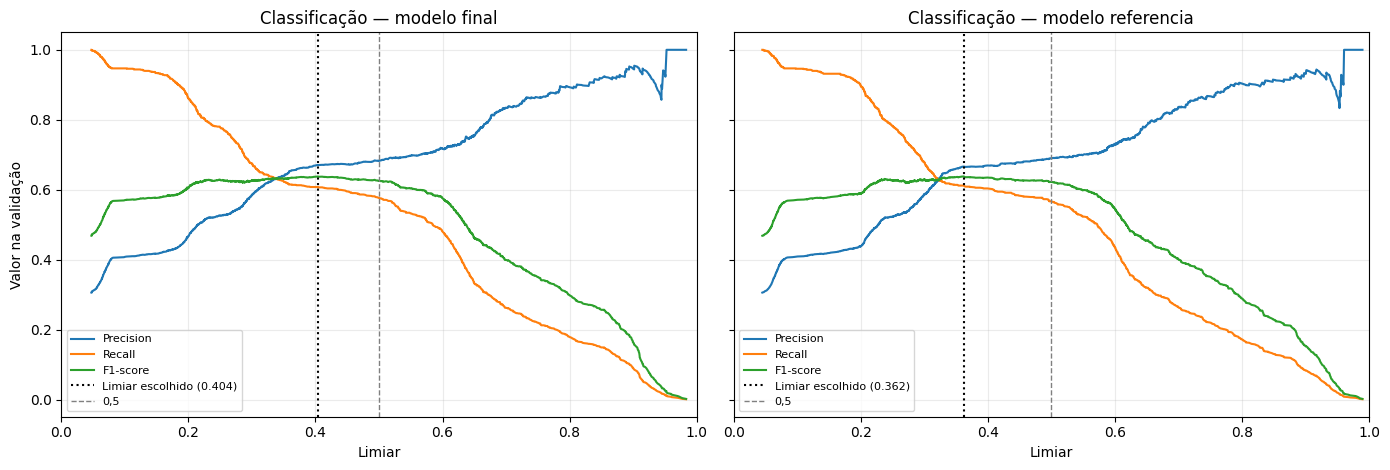

Modelo,Ponto,Limiar,Precision,Recall,F1-score,Accuracy,Previstos positivos (%)
final,Limiar escolhido,0.4038,0.6708,0.6078,0.6377,0.7887,27.7187
final,"Limiar 0,5 (comparação)",0.5000,0.6828,0.5761,0.6249,0.7884,25.8125
referencia,Limiar escolhido,0.3621,0.6663,0.6118,0.6379,0.7875,28.0938
referencia,"Limiar 0,5 (comparação)",0.5000,0.6899,0.5659,0.6218,0.7894,25.0937


In [8]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

dt_c = DADOS_TAREFA["classificacao"]
y_val_c = dt_c["y_original"]["validacao"]
LIMIAR, linhas_limiar = {}, []
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)

for eixo, papel in zip(eixos, ("final", "referencia")):
    prob = expit(treino.prever(REDES[("classificacao", papel)], dt_c["X"]["validacao"], DEVICE).astype(np.float64))
    precisao, recall, limiares = precision_recall_curve(y_val_c, prob)
    p, r = precisao[:-1], recall[:-1]                     # alinhados com `limiares`
    f1 = np.where(p + r > 0, 2 * p * r / np.where(p + r > 0, p + r, 1), 0.0)
    melhores = np.flatnonzero(f1 == f1.max())
    i = melhores[np.argmin(limiares[melhores])]          # desempate: menor limiar
    LIMIAR[papel] = float(limiares[i])

    m_escolhido = metricas.calcular_metricas_classificacao(y_val_c, prob, LIMIAR[papel])
    m_05 = metricas.calcular_metricas_classificacao(y_val_c, prob, 0.5)
    for nome, m in [("Limiar escolhido", m_escolhido), ("Limiar 0,5 (comparação)", m_05)]:
        linhas_limiar.append({"Modelo": papel, "Ponto": nome, "Limiar": m["limiar"],
                              "Precision": m["Precision"], "Recall": m["Recall"], "F1-score": m["F1-score"],
                              "Accuracy": m["Accuracy"], "Previstos positivos (%)": 100 * (prob >= m["limiar"]).mean()})

    eixo.plot(limiares, p, label="Precision")
    eixo.plot(limiares, r, label="Recall")
    eixo.plot(limiares, f1, label="F1-score")
    eixo.axvline(LIMIAR[papel], color="black", linestyle=":", label=f"Limiar escolhido ({LIMIAR[papel]:.3f})")
    eixo.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="0,5")
    eixo.set_xlim(0, 1); eixo.set_xlabel("Limiar"); eixo.set_title(f"Classificação — modelo {papel}")
    eixo.grid(alpha=0.25); eixo.legend(fontsize=8)
eixos[0].set_ylabel("Valor na validação")
fig.tight_layout()
fig.savefig(pasta_figuras / "modelos_finais_limiar_validacao.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

tabela_limiar = pd.DataFrame(linhas_limiar)
display(tabela_limiar.style.format(precision=4).hide(axis="index"))

## 4. Congelamento antes do contato com o teste

Antes de qualquer uso do conjunto de teste, registram-se, para cada modelo, a configuração, a semente, o limiar (na classificação) e uma **impressão digital dos pesos**: o SHA-256 dos tensores do `state_dict`. Depois da avaliação no teste, os pesos carregados dos arquivos devem ter exatamente a mesma impressão digital, o que demonstra que nenhum modelo foi alterado após o contato com o teste. O Notebook 07 repete essa verificação antes de avaliar.

In [9]:
import datetime

def impressao_digital(state_dict):
    h = hashlib.sha256()
    for nome, tensor in state_dict.items():
        h.update(nome.encode("utf-8"))
        h.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

CONGELAMENTO = {}
for (problema, papel), modelo in REDES.items():
    CONGELAMENTO[f"{problema}/{papel}"] = {
        "config_id": treino.id_configuracao(MODELOS[(problema, papel)]),
        "semente": SEMENTE[(problema, papel)],
        "limiar": LIMIAR.get(papel) if problema == "classificacao" else None,
        "sha256_pesos": impressao_digital(modelo.state_dict()),
    }
CONGELAMENTO["registrado_em"] = datetime.datetime.now().isoformat(timespec="seconds")
with open(pasta_logs / "congelamento_modelos.json", "w", encoding="utf-8") as f:
    json.dump(CONGELAMENTO, f, ensure_ascii=False, indent=2)
print("Congelamento registrado em logs/congelamento_modelos.json (antes de qualquer uso do teste).")
display(pd.DataFrame({k: v for k, v in CONGELAMENTO.items() if k != "registrado_em"}).T)

Congelamento registrado em logs/congelamento_modelos.json (antes de qualquer uso do teste).


,config_id,semente,limiar,sha256_pesos
regressao/final,cfg_a7f13b5c34,2,None,63de314394e96c5c2fddab8a1f00dadb9ea7ea95df1fad...
regressao/referencia,cfg_8dff8c8b84,3,None,1468ab31c372fa7e654fd306b1916394f1088ad58e1162...
classificacao/final,cfg_a7f13b5c34,4,0.403776,bb224fac09bccb765bc9ed01f11610f462a453601e2c22...
classificacao/referencia,cfg_8dff8c8b84,3,0.362136,26e22e211b2ee466bfdfbddfa24a0e3d72a9922fa227fe...


## 5. Avaliação em memória, antes do salvamento

Com os modelos congelados (Seção 4), inicia-se a etapa de avaliação final, realizada uma única vez e dividida em duas partes: nesta seção, as saídas dos modelos **em memória** são calculadas **antes de salvar** os arquivos; na Seção 7, os mesmos cálculos são repetidos com os modelos **carregados** dos arquivos, em um processo separado. Os quatro modelos (finais e de referência) são avaliados com pesos e limiares já fixados, e nenhum resultado desta etapa é usado para alterar escolhas: a repetição da inferência serve apenas para a verificação de fidelidade.

O teste é transformado com o pré-processamento ajustado no subconjunto de ajuste, e a métrica principal é calculada na validação e no teste (RMSE na regressão; AP na classificação). As saídas completas ficam guardadas em memória para a comparação da Seção 7.

In [10]:
pasta_temp = Path(tempfile.mkdtemp())          # fora do Drive: arquivos de trabalho do processo limpo
X_bruto = {"validacao": dados["X_validacao"], "teste": dados["X_teste"]}
y_real = {("regressao", c): dados[f"y_{c}_r"].to_numpy(np.float64) for c in X_bruto}
y_real.update({("classificacao", c): dados[f"y_{c}_c"].to_numpy(np.int64) for c in X_bruto})

def saida_em_memoria(problema, papel, conjunto):
    dt = DADOS_TAREFA[problema]
    X = dt["preprocessador"].transform(X_bruto[conjunto]).astype(np.float32)
    s = treino.prever(REDES[(problema, papel)], X, DEVICE).astype(np.float64)
    return pipeline_data.despadronizar_alvo(s, dt["escala_alvo"]) if problema == "regressao" else expit(s)

def metrica(problema, papel, conjunto, saida):
    if problema == "regressao":
        return metricas.calcular_metricas_regressao(y_real[(problema, conjunto)], saida)["RMSE"]
    return metricas.calcular_metricas_classificacao(y_real[(problema, conjunto)], saida, LIMIAR[papel])["Average_Precision"]

ANTES = {(p, papel, c): saida_em_memoria(p, papel, c)
         for (p, papel) in MODELOS for c in ("validacao", "teste")}
tabela_antes = pd.DataFrame([{
    "Problema": p, "Papel": papel, "Conjunto": c, "Métrica": "RMSE" if p == "regressao" else "AP",
    "Valor antes de salvar": metrica(p, papel, c, saida)} for (p, papel, c), saida in ANTES.items()])
display(tabela_antes.style.format({"Valor antes de salvar": "{:.6f}"}).hide(axis="index"))

Problema,Papel,Conjunto,Métrica,Valor antes de salvar
regressao,final,validacao,RMSE,2.952189
regressao,final,teste,RMSE,2.968563
regressao,referencia,validacao,RMSE,2.954544
regressao,referencia,teste,RMSE,2.975073
classificacao,final,validacao,AP,0.687980
classificacao,final,teste,AP,0.690012
classificacao,referencia,validacao,AP,0.687484
classificacao,referencia,teste,AP,0.689977


## 6. Checkpoints

Cada arquivo `.pt` guarda tudo o que é necessário para usar o modelo fora deste notebook: o `state_dict` (pesos e vieses), os hiperparâmetros da arquitetura (para recriar a rede), a ordem das features, os mapeamentos das categorias, as medianas de imputação, a média e o desvio de padronização das features e, na regressão, a média e o desvio do alvo; na classificação, os nomes das classes, o limiar e o critério usado para escolhê-lo. Sem essas estatísticas, o modelo carregado receberia entradas em outra escala e produziria previsões erradas.

Todos os valores são tensores ou tipos simples (números, textos, listas e dicionários), o que permite carregar os arquivos com `torch.load(..., weights_only=True)`. Os pesos gravados são os mesmos registrados no congelamento da Seção 4; a impressão digital é conferida novamente após o carregamento (Seção 7).

**Por que salvar o `state_dict`, e não o modelo inteiro.** `torch.save(modelo)` serializa o objeto Python com *pickle*: o arquivo fica acoplado à definição da classe e ao caminho do módulo em que ela estava, e tende a quebrar quando o código muda. Além disso, carregar um *pickle* executa código: um arquivo malicioso pode executar comandos arbitrários ao ser aberto. O `state_dict` contém apenas tensores; para usá-lo, recria-se a arquitetura a partir da configuração e carregam-se os pesos. O parâmetro `weights_only=True` restringe o carregamento a esses tipos seguros (Seção 8.1).

In [11]:
CAMINHOS = {
    ("regressao", "final"): pasta_modelos / "modelo_regressao.pt",
    ("classificacao", "final"): pasta_modelos / "modelo_classificacao.pt",
    ("regressao", "referencia"): pasta_referencia / "baseline_regressao.pt",
    ("classificacao", "referencia"): pasta_referencia / "baseline_classificacao.pt",
}

def montar_checkpoint(problema, papel):
    modelo, dt = REDES[(problema, papel)], DADOS_TAREFA[problema]
    _, registro = RESULTADOS[(problema, papel)]
    est = dt["estatisticas"]
    ckpt = {
        "state_dict": modelo.state_dict(),
        "config": dict(modelo.config),
        "tarefa": problema,
        "features": list(est["features"]),
        "categorias": {k: list(v) for k, v in est["categorias"].items()},
        "mediana_imputacao": {k: float(v) for k, v in est["mediana_imputacao"].items()},
        "x_media": [float(v) for v in est["x_media"]],
        "x_desvio": [float(v) for v in est["x_desvio"]],
        "metadados": {
            "papel": papel, "config_id": treino.id_configuracao(MODELOS[(problema, papel)]),
            "hiperparametros_treino": {k: (list(v) if isinstance(v, tuple) else v)
                                       for k, v in MODELOS[(problema, papel)].items()},
            "semente": SEMENTE[(problema, papel)], "n_parametros": int(registro["n_parametros"]),
            "epoca_melhor": int(registro["epoca_melhor"]),
            "metricas_validacao": {k: float(v) for k, v in registro["metricas_validacao"].items()
                                   if k not in ("Confusion_Matrix", "limiar")},
            "torch": str(torch.__version__), "python": platform.python_version(),
            "cpu": treino.modelo_cpu(), "data": datetime.date.today().isoformat(),
        },
    }
    if problema == "regressao":
        ckpt["y_media"] = float(dt["escala_alvo"]["y_media"])
        ckpt["y_desvio"] = float(dt["escala_alvo"]["y_desvio"])
    else:
        ckpt["classes"] = ["Ausência (0)", "Presença (1)"]
        ckpt["limiar"] = LIMIAR[papel]
        ckpt["criterio_limiar"] = "F1 máximo na validação; empate: menor limiar"
    return ckpt

linhas_arquivos = []
for chave, caminho in CAMINHOS.items():
    torch.save(montar_checkpoint(*chave), caminho)
    n_par = modelos_mlp.contar_parametros(REDES[chave])
    tamanho = caminho.stat().st_size
    linhas_arquivos.append({
        "Problema": chave[0], "Papel": chave[1], "Arquivo": str(caminho.relative_to(PROJETO)),
        "Parâmetros": n_par, "Pesos em float32 (KB)": n_par * 4 / 1024,
        "Tamanho em disco (KB)": tamanho / 1024, "Overhead (KB)": (tamanho - n_par * 4) / 1024,
        "sha256_arquivo": hashlib.sha256(caminho.read_bytes()).hexdigest(),
    })
tabela_arquivos = pd.DataFrame(linhas_arquivos)
display(tabela_arquivos.drop(columns="sha256_arquivo").style.format(precision=2).hide(axis="index"))

for linha in linhas_arquivos:
    CONGELAMENTO[f"{linha['Problema']}/{linha['Papel']}"]["sha256_arquivo"] = linha["sha256_arquivo"]
with open(pasta_logs / "congelamento_modelos.json", "w", encoding="utf-8") as f:
    json.dump(CONGELAMENTO, f, ensure_ascii=False, indent=2)

Problema,Papel,Arquivo,Parâmetros,Pesos em float32 (KB),Tamanho em disco (KB),Overhead (KB)
regressao,final,models/modelo_regressao.pt,1313,5.13,9.56,4.43
classificacao,final,models/modelo_classificacao.pt,1313,5.13,9.86,4.73
regressao,referencia,models/referencia/baseline_regressao.pt,1313,5.13,9.59,4.46
classificacao,referencia,models/referencia/baseline_classificacao.pt,1313,5.13,9.95,4.82


**Tamanho do arquivo.** Cada parâmetro em `float32` ocupa 4 bytes; para 1.313 parâmetros, os pesos ocupam cerca de 5 KB. O tamanho em disco é maior por causa do *overhead*: a estrutura do arquivo (formato zip do `torch.save`, nomes dos tensores) e os metadados guardados no checkpoint (configuração, estatísticas de pré-processamento e informações de procedência). Para uma rede pequena como esta, o *overhead* é uma parcela grande do arquivo; em redes com milhões de parâmetros, o tamanho seria dominado pelos pesos.

## 7. Carregamento em ambiente limpo e verificação de fidelidade

O script `src/inference.py` é executado em um **processo separado**, que não compartilha nenhuma variável com este notebook. Ele carrega cada arquivo com `map_location="cpu"` e `weights_only=True`, coloca o modelo em modo de avaliação, aplica o pré-processamento guardado no checkpoint a amostras em unidades originais e grava as previsões. Essas previsões são comparadas com as obtidas em memória antes do salvamento (Seção 5).

A fidelidade é verificada por três critérios: igualdade das saídas (`torch.allclose` e diferença máxima absoluta), igualdade da métrica (diferença absoluta entre as métricas, com `numpy.isclose` como critério de aceitação) e igualdade da impressão digital dos pesos carregados com a registrada no congelamento. A verificação é feita na validação e no teste. O script grava as saídas com 17 algarismos significativos e elas são lidas com `float_precision="round_trip"`; sem essa opção, o leitor padrão do pandas pode alterar o último dígito binário de alguns valores, o que introduziria diferenças da ordem de $10^{-15}$ que não vêm do modelo. Os valores do teste são reutilizados no Notebook 07, que apresenta a avaliação completa, sem nova inferência.

In [12]:
for c, X in X_bruto.items():
    X.to_csv(pasta_temp / f"entrada_{c}.csv", index=False)

def saida_processo_limpo(problema, papel, conjunto):
    destino = pasta_temp / f"saida_{problema}_{papel}_{conjunto}.csv"
    r = subprocess.run([sys.executable, str(PROJETO / "src" / "inference.py"),
                        "--modelo", str(CAMINHOS[(problema, papel)]),
                        "--entrada", str(pasta_temp / f"entrada_{conjunto}.csv"),
                        "--saida", str(destino)], capture_output=True, text=True)
    assert r.returncode == 0, r.stderr
    s = pd.read_csv(destino, float_precision="round_trip")
    coluna = "Risk_Score_previsto" if problema == "regressao" else "probabilidade_classe_1"
    return s[coluna].to_numpy(np.float64), s

linhas_fid, PREVISOES_TESTE = [], []
for (problema, papel) in CAMINHOS:
    for conjunto in ("validacao", "teste"):
        antes = ANTES[(problema, papel, conjunto)]
        depois, tabela_saida = saida_processo_limpo(problema, papel, conjunto)
        linhas_fid.append({
            "Problema": problema, "Papel": papel, "Conjunto": conjunto,
            "Métrica": "RMSE" if problema == "regressao" else "AP",
            "Antes de salvar (memória)": metrica(problema, papel, conjunto, antes),
            "Carregado (processo limpo)": metrica(problema, papel, conjunto, depois),
            "torch.allclose": torch.allclose(torch.from_numpy(antes), torch.from_numpy(depois), rtol=0, atol=1e-6),
            "Diferença máxima absoluta": float(np.max(np.abs(antes - depois))),
        })
        if conjunto == "teste":
            registro = pd.DataFrame({"problema": problema, "papel": papel,
                                     "indice_original": X_bruto["teste"].index.to_numpy(),
                                     "y_real": y_real[(problema, "teste")], "saida": depois})
            if problema == "classificacao":
                registro["classe_prevista"] = tabela_saida["classe_prevista"].to_numpy()
            PREVISOES_TESTE.append(registro)

tabela_fidelidade = pd.DataFrame(linhas_fid)
tabela_fidelidade["Diferença da métrica"] = (tabela_fidelidade["Antes de salvar (memória)"]
                                             - tabela_fidelidade["Carregado (processo limpo)"]).abs()
tabela_fidelidade["Métrica equivalente"] = np.isclose(tabela_fidelidade["Antes de salvar (memória)"],
                                                      tabela_fidelidade["Carregado (processo limpo)"],
                                                      rtol=0, atol=1e-9)
display(tabela_fidelidade.style.format({"Antes de salvar (memória)": "{:.6f}", "Carregado (processo limpo)": "{:.6f}",
                                        "Diferença máxima absoluta": "{:.2e}", "Diferença da métrica": "{:.2e}"}).hide(axis="index"))
assert tabela_fidelidade["torch.allclose"].all() and tabela_fidelidade["Métrica equivalente"].all()

Problema,Papel,Conjunto,Métrica,Antes de salvar (memória),Carregado (processo limpo),torch.allclose,Diferença máxima absoluta,Diferença da métrica,Métrica equivalente
regressao,final,validacao,RMSE,2.952189,2.952189,True,0.00e+00,0.00e+00,True
regressao,final,teste,RMSE,2.968563,2.968563,True,0.00e+00,0.00e+00,True
classificacao,final,validacao,AP,0.687980,0.687980,True,0.00e+00,0.00e+00,True
classificacao,final,teste,AP,0.690012,0.690012,True,0.00e+00,0.00e+00,True
regressao,referencia,validacao,RMSE,2.954544,2.954544,True,0.00e+00,0.00e+00,True
regressao,referencia,teste,RMSE,2.975073,2.975073,True,0.00e+00,0.00e+00,True
classificacao,referencia,validacao,AP,0.687484,0.687484,True,0.00e+00,0.00e+00,True
classificacao,referencia,teste,AP,0.689977,0.689977,True,0.00e+00,0.00e+00,True


In [13]:
# Impressão digital dos pesos carregados de cada arquivo = registrada no congelamento (antes do teste)
linhas_digital = []
for (problema, papel), caminho in CAMINHOS.items():
    _, ckpt = inferencia.carregar_modelo(caminho)
    chave = f"{problema}/{papel}"
    linhas_digital.append({
        "Modelo": chave,
        "Pesos carregados = congelamento": impressao_digital(ckpt["state_dict"]) == CONGELAMENTO[chave]["sha256_pesos"],
        "Arquivo inalterado": hashlib.sha256(caminho.read_bytes()).hexdigest() == CONGELAMENTO[chave]["sha256_arquivo"],
    })
tabela_digital = pd.DataFrame(linhas_digital)
display(tabela_digital.style.hide(axis="index"))
assert tabela_digital.drop(columns="Modelo").all().all()

# Previsões do teste dos modelos carregados: reutilizadas no Notebook 07 (sem nova inferência no teste)
previsoes_teste = pd.concat(PREVISOES_TESTE, ignore_index=True)
caminho_prev = pasta_logs / "previsoes_teste.csv"
previsoes_teste.to_csv(caminho_prev, index=False, float_format="%.17g")
CONGELAMENTO["sha256_previsoes_teste"] = hashlib.sha256(caminho_prev.read_bytes()).hexdigest()
with open(pasta_logs / "congelamento_modelos.json", "w", encoding="utf-8") as f:
    json.dump(CONGELAMENTO, f, ensure_ascii=False, indent=2)
print("Previsões do teste gravadas em", caminho_prev.relative_to(PROJETO), "| linhas:", len(previsoes_teste))

Modelo,Pesos carregados = congelamento,Arquivo inalterado
regressao/final,True,True
classificacao/final,True,True
regressao/referencia,True,True
classificacao/referencia,True,True


Previsões do teste gravadas em logs/previsoes_teste.csv | linhas: 16000


## 8. Demonstrações de boas práticas

### 8.1 `weights_only=True` e o modelo inteiro em *pickle*

Para mostrar o risco sem lidar com arquivos de origem desconhecida, salva-se aqui, em uma pasta temporária, o modelo **inteiro** com `torch.save(modelo, ...)`. Com `weights_only=True`, o carregamento é recusado, porque o arquivo contém um objeto Python, e não apenas tensores. Carregar esse arquivo exigiria `weights_only=False`, que executa o *pickle* — aceitável apenas para arquivos de origem confiável. O checkpoint do projeto, por conter somente tensores e tipos simples, é carregado normalmente com `weights_only=True`.

In [14]:
arquivo_inteiro = pasta_temp / "modelo_inteiro_demo.pt"
torch.save(REDES[("regressao", "final")], arquivo_inteiro)
try:
    torch.load(arquivo_inteiro, map_location="cpu", weights_only=True)
    print("Inesperado: o modelo inteiro foi carregado com weights_only=True")
except Exception as erro:
    print("weights_only=True recusou o modelo inteiro:", type(erro).__name__)
    print(" ", str(erro).splitlines()[0][:160])

ckpt_regressao = torch.load(CAMINHOS[("regressao", "final")], map_location="cpu", weights_only=True)
print("\nCheckpoint do projeto carregado com weights_only=True. Chaves:", sorted(ckpt_regressao))

weights_only=True recusou o modelo inteiro: UnpicklingError
  Weights only load failed. This file can still be loaded, to do so you have two options, do those steps only if you trust the source of the checkpoint. 

Checkpoint do projeto carregado com weights_only=True. Chaves: ['categorias', 'config', 'features', 'mediana_imputacao', 'metadados', 'state_dict', 'tarefa', 'x_desvio', 'x_media', 'y_desvio', 'y_media']


### 8.2 O que acontece ao esquecer `model.eval()`

Esta é uma **demonstração didática**, à parte dos modelos salvos. Como o modelo final não usa *dropout*, treina-se aqui um modelo auxiliar: a configuração de referência com o *dropout* alterado de 0 para 0,3 (um dos valores do estudo isolado de *dropout*), com a semente 0. Esse modelo não é salvo nem comparado com os demais. Em modo de treinamento (`model.train()`), o *dropout* zera aleatoriamente 30% das ativações a cada chamada: a mesma amostra recebe previsões diferentes a cada execução, e o desempenho piora porque a rede opera com parte dos neurônios desligados. Em modo de avaliação (`model.eval()`), o *dropout* é desativado e as previsões são determinísticas. Em redes com Batch Normalization, esquecer o `eval()` também faria a rede usar as estatísticas do lote atual em vez das estatísticas acumuladas no treinamento.

In [15]:
dt_r = DADOS_TAREFA["regressao"]
rede_dropout, _, _ = treino.executar_configuracao(dt_r, {"dropout": 0.3}, 0, device=DEVICE)
X5 = torch.as_tensor(dt_r["X"]["validacao"][:5])

def prever_escala_original(modelo):
    with torch.no_grad():
        return pipeline_data.despadronizar_alvo(modelo(X5).squeeze(1).double().numpy(), dt_r["escala_alvo"])

torch.manual_seed(123)
rede_dropout.train()
chamadas_treino = [prever_escala_original(rede_dropout) for _ in range(3)]
rede_dropout.eval()
chamadas_eval = [prever_escala_original(rede_dropout) for _ in range(3)]

demo = pd.DataFrame({
    **{f"train() chamada {i+1}": c for i, c in enumerate(chamadas_treino)},
    **{f"eval() chamada {i+1}": c for i, c in enumerate(chamadas_eval)},
}, index=[f"amostra {i+1}" for i in range(5)])
display(demo.style.format("{:.4f}"))

Xv = dt_r["X"]["validacao"]; yv = dt_r["y_original"]["validacao"]
rede_dropout.train()
with torch.no_grad():
    rmse_train = metricas.calcular_metricas_regressao(
        yv, pipeline_data.despadronizar_alvo(rede_dropout(torch.as_tensor(Xv)).squeeze(1).double().numpy(), dt_r["escala_alvo"]))["RMSE"]
rede_dropout.eval()
rmse_eval = metricas.calcular_metricas_regressao(
    yv, pipeline_data.despadronizar_alvo(treino.prever(rede_dropout, Xv, DEVICE), dt_r["escala_alvo"]))["RMSE"]
print(f"RMSE de validação — modo train(): {rmse_train:.4f} | modo eval(): {rmse_eval:.4f}")

,train() chamada 1,train() chamada 2,train() chamada 3,eval() chamada 1,eval() chamada 2,eval() chamada 3
amostra 1,5.4382,7.8097,6.9726,6.6647,6.6647,6.6647
amostra 2,11.7593,10.9718,11.5986,11.1497,11.1497,11.1497
amostra 3,8.1472,7.4723,6.9582,7.7326,7.7326,7.7326
amostra 4,7.2295,6.3841,6.5354,6.7204,6.7204,6.7204
amostra 5,12.0041,13.6060,12.1785,12.4214,12.4214,12.4214


RMSE de validação — modo train(): 3.0181 | modo eval(): 2.9567


### 8.3 Portabilidade: `map_location`

Os arquivos são carregados com `map_location="cpu"`, que coloca todos os tensores na CPU independentemente de onde o modelo foi treinado. Se o treinamento tivesse ocorrido em GPU, os tensores do `state_dict` estariam associados ao dispositivo `cuda`; sem `map_location`, o carregamento em uma máquina sem GPU falharia. Para usar a GPU na inferência, bastaria carregar com `map_location="cuda"` (ou mover o modelo com `modelo.to("cuda")`) e enviar as entradas ao mesmo dispositivo.

In [16]:
modelo_carregado, _ = inferencia.carregar_modelo(CAMINHOS[("classificacao", "final")])
print("Dispositivo dos parâmetros carregados:", {p.device.type for p in modelo_carregado.parameters()})
print("Modo de avaliação ativo (modelo.training == False):", not modelo_carregado.training)

Dispositivo dos parâmetros carregados: {'cpu'}
Modo de avaliação ativo (modelo.training == False): True


## 9. Uso do script de inferência com amostras de exemplo

O arquivo `data/exemplo_amostras_inferencia.csv` contém quatro **amostras de exemplo sem os alvos**, em unidades originais. Elas foram retiradas do subconjunto de validação e não são registros novos nem independentes: servem apenas para demonstrar o uso do script e do pré-processamento guardado no checkpoint; em um deles, a glicose foi removida para mostrar a imputação pela mediana guardada no checkpoint. O script é executado pela linha de comando, como faria um usuário do modelo, e uma entrada com categoria inválida é usada para mostrar a validação dos dados.

In [17]:
exemplo = dados["X_validacao"].head(4).copy().reset_index(drop=True)
exemplo.loc[3, "Blood_Glucose"] = np.nan
caminho_exemplo = PROJETO / "data" / "exemplo_amostras_inferencia.csv"
exemplo.to_csv(caminho_exemplo, index=False)
display(exemplo)

for arquivo in ("models/modelo_regressao.pt", "models/modelo_classificacao.pt"):
    r = subprocess.run([sys.executable, "src/inference.py", "--modelo", arquivo,
                        "--entrada", "data/exemplo_amostras_inferencia.csv"],
                       capture_output=True, text=True, cwd=PROJETO)
    print(f"$ python src/inference.py --modelo {arquivo} --entrada data/exemplo_amostras_inferencia.csv")
    print(r.stdout if r.returncode == 0 else r.stderr)

invalida = exemplo.head(1).copy()
invalida.loc[0, "Diabetes"] = "Talvez"
modelo_c, ckpt_c = inferencia.carregar_modelo(CAMINHOS[("classificacao", "final")])
try:
    inferencia.prever(invalida, modelo_c, ckpt_c)
except ValueError as erro:
    print("Entrada inválida rejeitada:", erro)

,Diabetes,Hypertension,Chest_Pain,ECG_Result,Blood_Glucose,Blood_Pressure_Systolic
0,No,No,No,Normal,113.0,107
1,No,Yes,Yes,Normal,68.0,115
2,No,Yes,No,Normal,116.0,103
3,No,No,No,Normal,NaN,118


$ python src/inference.py --modelo models/modelo_regressao.pt --entrada data/exemplo_amostras_inferencia.csv
Modelo: models/modelo_regressao.pt | tarefa: regressao
Diabetes Hypertension Chest_Pain ECG_Result  Blood_Glucose  Blood_Pressure_Systolic  Risk_Score_previsto
      No           No         No     Normal          113.0                      107             6.483219
      No          Yes        Yes     Normal           68.0                      115            11.291250
      No          Yes         No     Normal          116.0                      103             8.221674
      No           No         No     Normal            NaN                      118             6.382626

$ python src/inference.py --modelo models/modelo_classificacao.pt --entrada data/exemplo_amostras_inferencia.csv
Modelo: models/modelo_classificacao.pt | tarefa: classificacao
Limiar de decisão: 0.4038
Diabetes Hypertension Chest_Pain ECG_Result  Blood_Glucose  Blood_Pressure_Systolic  probabilidade_classe_1 

## 10. Exportação

In [18]:
tabelas = {
    "modelos_finais_treino.csv": tabela_treino,
    "modelos_finais_limiar.csv": tabela_limiar,
    "modelos_finais_arquivos.csv": tabela_arquivos,
    "modelos_finais_fidelidade.csv": tabela_fidelidade,
}
for nome, tabela in tabelas.items():
    tabela.to_csv(pasta_tabelas / nome, index=False, encoding="utf-8-sig", float_format="%.16g")
    print("Salvo:", (pasta_tabelas / nome).relative_to(PROJETO))
print("\nArquivos de modelo:")
for caminho in CAMINHOS.values():
    print(" ", caminho.relative_to(PROJETO), f"({caminho.stat().st_size / 1024:.1f} KB)")

Salvo: reports/tables/modelos_finais_treino.csv
Salvo: reports/tables/modelos_finais_limiar.csv
Salvo: reports/tables/modelos_finais_arquivos.csv
Salvo: reports/tables/modelos_finais_fidelidade.csv

Arquivos de modelo:
  models/modelo_regressao.pt (9.6 KB)
  models/modelo_classificacao.pt (9.9 KB)
  models/referencia/baseline_regressao.pt (9.6 KB)
  models/referencia/baseline_classificacao.pt (9.9 KB)


## 11. Síntese

**Reprodutibilidade.** Treinados novamente com a semente mediana, os quatro modelos reproduziram exatamente a métrica de validação registrada no estudo de hiperparâmetros, no mesmo processador. Os modelos salvos são, portanto, os mesmos que foram avaliados na seleção, e não uma nova amostra do processo de treinamento.

**Limiar de decisão.** Nos dois modelos de classificação, o limiar de F1 máximo ficou abaixo de 0,5 (cerca de 0,40 no modelo final e 0,36 no de referência). Em relação a 0,5, ele aumenta o Recall em alguns pontos percentuais, com perda menor de Precision; o F1 sobe pouco (cerca de 0,01) e a Accuracy praticamente não muda. O limiar é diferente para cada modelo, o que mostra que ele é uma propriedade do modelo treinado e precisa ser guardado junto com os pesos. Como o limiar foi escolhido na mesma validação usada na seleção, o F1 de validação nesse ponto é otimista; o desempenho com o limiar congelado é medido no teste, no Notebook 07. O limiar é um ponto de operação experimental, e não um limiar clínico.

**Persistência e fidelidade.** Cada checkpoint reúne os pesos, a arquitetura e todo o pré-processamento (codificação, imputação, padronização das features e, na regressão, do alvo). Carregados em um processo separado, sem acesso às variáveis deste notebook, com `weights_only=True` e `map_location="cpu"`, os modelos reproduziram as saídas e as métricas obtidas em memória antes do salvamento, na validação e no teste; as diferenças máximas estão registradas na tabela de fidelidade. As impressões digitais dos pesos carregados coincidem com as registradas antes do contato com o teste, o que documenta que nenhum modelo foi alterado depois desse contato. A fidelidade depende de o código da classe `MLP` (`src/models.py`) ser o mesmo usado no treinamento, já que o `state_dict` guarda apenas os valores dos parâmetros.

**Boas práticas demonstradas.** O carregamento com `weights_only=True` recusou o arquivo com o modelo inteiro em *pickle* e aceitou o checkpoint do projeto, que contém apenas tensores e tipos simples. Na rede com *dropout*, esquecer o `model.eval()` fez a mesma amostra receber previsões diferentes a cada chamada e piorou o RMSE de validação; em modo de avaliação, as previsões foram determinísticas.

**Teste.** Os valores do teste calculados aqui servem apenas à verificação de fidelidade; nenhuma decisão foi tomada com base neles. A avaliação completa, a comparação com o modelo de referência e a análise de generalização estão no Notebook 07, que reutiliza as previsões gravadas em `logs/previsoes_teste.csv`.